## 1. Data Collection

This project uses a reproducible synthetic dataset of 300 student records. It includes Study Hours, Attendance, Previous Score, Assignments Score, and Final Marks.

The dataset was generated with scripts/generate_data.ps1. Since the records are synthetic, the model results are not validated for real students.

In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("data") / "student_performance.csv"
df = pd.read_csv(data_path)

df.shape

(300, 5)

## 2. Data Preprocessing

We inspect data types and missing values, separate the input features from Final Marks, split the data into training and test sets, and handle missing input values using medians calculated from the training set only.

In [2]:
print("\nFirst 5 rows:")
print(df.head())

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())


First 5 rows:
   Study Hours  Attendance  Previous Score  Assignments Score  Final Marks
0          3.7        81.0            62.0               43.0           63
1          1.2        66.0            36.0               77.0           59
2          6.9        94.0            52.0               41.0           77
3          1.6        59.0            85.0               86.0           78
4          0.5        73.0            95.0               48.0           59

Column data types:
Study Hours          float64
Attendance           float64
Previous Score       float64
Assignments Score    float64
Final Marks            int64
dtype: object

Missing values:
Study Hours           7
Attendance            9
Previous Score        8
Assignments Score    10
Final Marks           0
dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

feature_columns = [
    "Study Hours",
    "Attendance",
    "Previous Score",
    "Assignments Score"
]

X = df[feature_columns]
y = df["Final Marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

Training features: (240, 4)
Test features: (60, 4)
Training target: (240,)
Test target: (60,)


In [4]:
train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("Missing values in training features:")
print(X_train.isnull().sum())

print("\nMissing values in test features:")
print(X_test.isnull().sum())

Missing values in training features:
Study Hours          0
Attendance           0
Previous Score       0
Assignments Score    0
dtype: int64

Missing values in test features:
Study Hours          0
Attendance           0
Previous Score       0
Assignments Score    0
dtype: int64


## Data Preprocessing Summary

- The dataset was split into training and test sets before handling missing values to prevent data leakage.
- Median values were calculated using the training features only and applied to both sets.
- `Final Marks` was kept as the target and excluded from the input features.
- All input features are numeric, so categorical encoding was not needed.
- Feature scaling was not applied because it is not required for the selected regression models.

## 3. Exploratory Data Analysis (EDA)

Correlation between Study Hours and Final Marks: 0.49


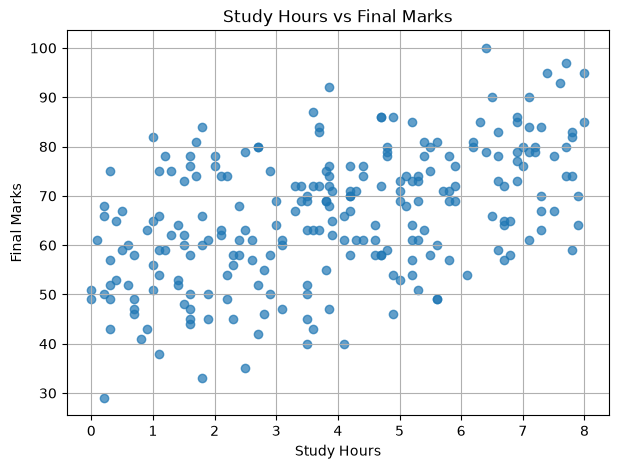

In [5]:
import matplotlib.pyplot as plt

study_hours_correlation = X_train["Study Hours"].corr(y_train)

print(
    "Correlation between Study Hours and Final Marks:",
    round(study_hours_correlation, 2)
)

plt.figure(figsize=(7, 5))
plt.scatter(X_train["Study Hours"], y_train, alpha=0.7)
plt.title("Study Hours vs Final Marks")
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.grid(True)
plt.show()

Correlation between Attendance and Final Marks: 0.19


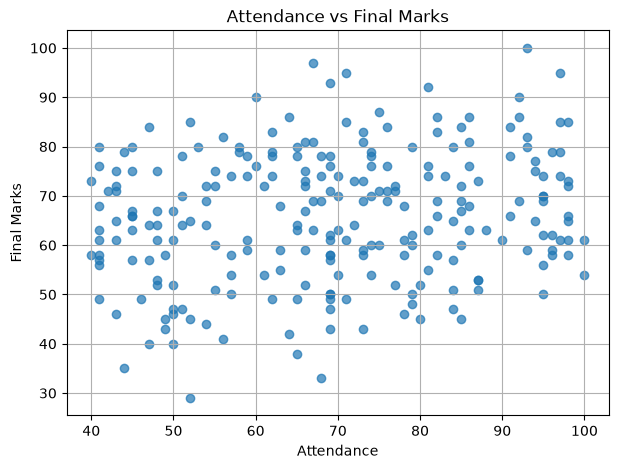

In [6]:
attendance_correlation = X_train["Attendance"].corr(y_train)

print(
    "Correlation between Attendance and Final Marks:",
    round(attendance_correlation, 2)
)

plt.figure(figsize=(7, 5))
plt.scatter(X_train["Attendance"], y_train, alpha=0.7)
plt.title("Attendance vs Final Marks")
plt.xlabel("Attendance")
plt.ylabel("Final Marks")
plt.grid(True)
plt.show()

Final Marks summary:
count    240.000000
mean      65.875000
std       13.238755
min       29.000000
25%       57.750000
50%       66.000000
75%       75.250000
max      100.000000
Name: Final Marks, dtype: float64


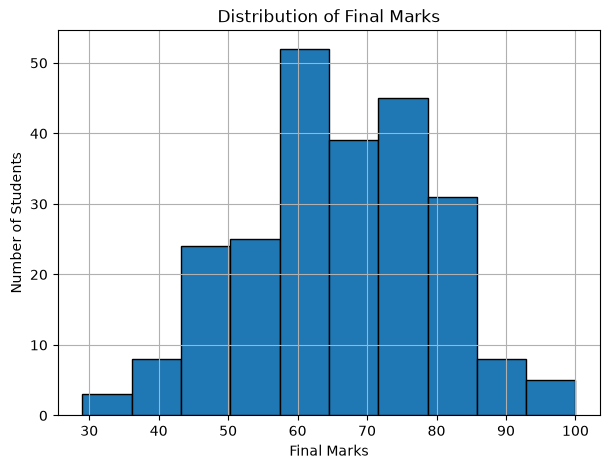

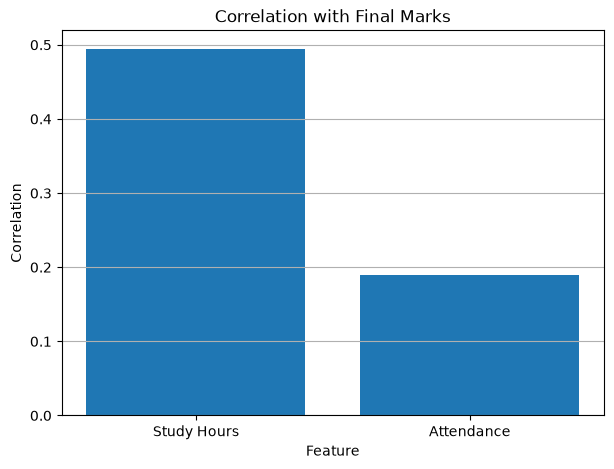

In [7]:
print("Final Marks summary:")
print(y_train.describe())

plt.figure(figsize=(7, 5))
plt.hist(y_train, bins=10, edgecolor="black")
plt.title("Distribution of Final Marks")
plt.xlabel("Final Marks")
plt.ylabel("Number of Students")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Study Hours", "Attendance"],
    [study_hours_correlation, attendance_correlation]
)
plt.title("Correlation with Final Marks")
plt.xlabel("Feature")
plt.ylabel("Correlation")
plt.grid(axis="y")
plt.show()